In [2]:
# Run this once in your Colab/notebook environment
!pip install -q lime shap imbalanced-learn xgboost ucimlrepo kaggle scipy statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 1.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [3]:
# ============================================================
# CELL 1 — INSTALL ALL DEPENDENCIES (run this FIRST, alone)
# ============================================================
!pip install -q \
    lime \
    shap \
    imbalanced-learn \
    xgboost \
    lightgbm \
    catboost \
    ucimlrepo \
    kagglehub \
    scipy \
    statsmodels \
    faiss-cpu \
    sentence-transformers \
    transformers \
    pytorch-tabnet \
    torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.2 MB/s eta 0:00:00


In [4]:
# ============================================================
# CELL 2 — VERIFY ALL IMPORTS WORK
# ============================================================
import importlib

packages = [
    "lime", "shap", "imblearn", "xgboost", "lightgbm", "catboost",
    "ucimlrepo", "kagglehub", "scipy", "statsmodels",
    "faiss", "sentence_transformers", "transformers",
    "pytorch_tabnet", "torch",
]

missing = []
for pkg in packages:
    try:
        importlib.import_module(pkg)
        print(f"[OK]   {pkg}")
    except ImportError as e:
        print(f"[FAIL] {pkg}: {e}")
        missing.append(pkg)

if missing:
    print(f"\n⚠️  Missing: {missing}")
    print("Try: !pip install -q " + " ".join(missing))
else:
    print("\n✅ All packages installed. Proceed to the main pipeline.")

[OK]   lime
[OK]   shap
[OK]   imblearn
[OK]   xgboost
[OK]   lightgbm
[OK]   catboost
[OK]   ucimlrepo
[OK]   kagglehub
[OK]   scipy
[OK]   statsmodels
[OK]   faiss
[OK]   sentence_transformers
[OK]   transformers
[OK]   pytorch_tabnet
[OK]   torch

✅ All packages installed. Proceed to the main pipeline.


In [5]:
"""
================================================================================
EXTENDED EXPLAINABLE HYBRID ENSEMBLE FRAMEWORK (FINAL)
15 Models
================================================================================
Datasets:
  1. IBM Telco Customer Churn Kaggle
  2. Statlog German Credit (UCI id=144)
  3. Superstore Sales
================================================================================
"""

import os, json, warnings, math, time
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, kendalltau

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              StackingClassifier, VotingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import (LogisticRegression, RidgeClassifier,
                                   Lasso, LinearRegression)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             matthews_corrcoef, brier_score_loss, confusion_matrix,
                             balanced_accuracy_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTENC, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import shap
import lime, lime.lime_tabular

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CONFIG = {
    "test_size": 0.20,
    "bootstrap_n": 1000,
    "explanation_n_customers": 30,
    "stability_perturbations": 5,
    "stability_jaccard_threshold": 0.60,
    "concordance_spearman_threshold": 0.50,
    "random_state": RANDOM_STATE,
}
RESULTS = {}


# ==============================================================================
# 1. DATASET LOADERS
# ==============================================================================
def _prep_telco(df):
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df = df.drop(columns=["customerID"], errors="ignore")
    df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
    return df, "Churn"


def load_telco():
    for c in ["telco_churn.csv", "WA_Fn-UseC_-Telco-Customer-Churn.csv"]:
        if os.path.exists(c):
            return _prep_telco(pd.read_csv(c))
    try:
        import kagglehub
        p = kagglehub.dataset_download("blastchar/telco-customer-churn")
        return _prep_telco(pd.read_csv(
            os.path.join(p, "WA_Fn-UseC_-Telco-Customer-Churn.csv")))
    except Exception:
        pass
    url = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp/"
           "master/data/Telco-Customer-Churn.csv")
    return _prep_telco(pd.read_csv(url))


def load_german_credit():
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=144)
    X, y = ds.data.features, ds.data.targets
    y_bin = (y[y.columns[0]] == 2).astype(int).rename("CreditRisk")
    return pd.concat([X, y_bin], axis=1), "CreditRisk"


def _prep_superstore(df):
    df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
    df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")
    df["Ship_Delay"] = (df["Ship Date"] - df["Order Date"]).dt.days
    g = df.groupby("Customer ID").agg(
        Total_Sales=("Sales", "sum"),
        Order_Count=("Order ID", "nunique"),
        Avg_Ship_Delay=("Ship_Delay", "mean"),
        Segment=("Segment", "first"),
        Region=("Region", "first"),
        Category_Diversity=("Category", "nunique"),
    ).reset_index()
    thr = g["Total_Sales"].quantile(0.75)
    g["HighValue"] = (g["Total_Sales"] >= thr).astype(int)
    g = g.drop(columns=["Customer ID", "Total_Sales"])
    return g, "HighValue"


def load_superstore():
    for c in ["train.csv", "superstore_train.csv"]:
        if os.path.exists(c):
            return _prep_superstore(pd.read_csv(c))
    import kagglehub
    p = kagglehub.dataset_download("rohitsahoo/sales-forecasting")
    return _prep_superstore(pd.read_csv(os.path.join(p, "train.csv")))


# ==============================================================================
# 2. PREPROCESSING
# ==============================================================================
def build_preprocessor(X):
    num = X.select_dtypes(include=[np.number]).columns.tolist()
    cat = X.select_dtypes(exclude=[np.number]).columns.tolist()
    np_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                        ("sc", StandardScaler())])
    cp_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                        ("oh", OneHotEncoder(handle_unknown="ignore",
                                             sparse_output=False))])
    return ColumnTransformer([("num", np_pipe, num),
                              ("cat", cp_pipe, cat)]), num, cat


def build_imbalance_pipeline(pre, clf, X_train):
    pre.fit(X_train)
    feats = pre.get_feature_names_out()
    cat_idx = [i for i, f in enumerate(feats) if f.startswith("cat__")]
    if not cat_idx:
        smote = SMOTE(random_state=CONFIG["random_state"], k_neighbors=5)
    else:
        smote = SMOTENC(categorical_features=cat_idx,
                        random_state=CONFIG["random_state"], k_neighbors=5)
    return ImbPipeline([("pre", pre), ("smote", smote), ("clf", clf)])


# ==============================================================================
# 3. CUSTOM PYTORCH MODELS
# ==============================================================================
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


class FTTransformer(nn.Module):
    def __init__(self, n_features, d_token=32, n_heads=4, n_layers=2, dropout=0.1):
        super().__init__()
        self.W = nn.Parameter(torch.randn(n_features, d_token) * 0.02)
        self.b = nn.Parameter(torch.zeros(n_features, d_token))
        self.cls = nn.Parameter(torch.randn(1, d_token) * 0.02)
        enc = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads,
                                          dropout=dropout, batch_first=True)
        self.transformer = nn.TransformerEncoder(enc, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.W.unsqueeze(0) + self.b.unsqueeze(0)
        cls = self.cls.unsqueeze(0).expand(x.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1)
        out = self.transformer(tokens)
        return self.head(out[:, 0, :]).squeeze(-1)


class WideAndDeep(nn.Module):
    def __init__(self, n_features, hidden=(64, 32), dropout=0.2):
        super().__init__()
        self.wide = nn.Linear(n_features, 1)
        layers, prev = [], n_features
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        self.deep = nn.Sequential(*layers)
        self.deep_out = nn.Linear(prev, 1)

    def forward(self, x):
        return (self.wide(x) + self.deep_out(self.deep(x))).squeeze(-1)


class TorchTabularClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, model_cls="ft", epochs=30, lr=1e-3,
                 batch_size=256, random_state=42):
        self.model_cls = model_cls
        self.epochs = epochs
        self.lr = lr
        self.batch_size = batch_size
        self.random_state = random_state

    def _build(self, n_features):
        torch.manual_seed(self.random_state)
        if self.model_cls == "ft":
            return FTTransformer(n_features).to(DEVICE)
        return WideAndDeep(n_features).to(DEVICE)

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)
        self.classes_ = np.array([0, 1])
        self.model_ = self._build(X.shape[1])
        opt = torch.optim.AdamW(self.model_.parameters(), lr=self.lr)
        loss_fn = nn.BCEWithLogitsLoss()
        ds = TensorDataset(torch.tensor(X), torch.tensor(y))
        dl = DataLoader(ds, batch_size=self.batch_size, shuffle=True)
        self.model_.train()
        for _ in range(self.epochs):
            for xb, yb in dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                opt.zero_grad()
                loss = loss_fn(self.model_(xb), yb)
                loss.backward()
                opt.step()
        return self

    def predict_proba(self, X):
        X = torch.tensor(np.asarray(X, dtype=np.float32)).to(DEVICE)
        self.model_.eval()
        with torch.no_grad():
            logits = self.model_(X).cpu().numpy()
        p = 1 / (1 + np.exp(-logits))
        return np.vstack([1 - p, p]).T

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# ==============================================================================
# 4. RAG (FAISS-kNN), SBERT
# ==============================================================================
class RAGFAISSClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, k=15):
        self.k = k

    def fit(self, X, y):
        import faiss
        X = np.asarray(X, dtype=np.float32)
        self.y_ = np.asarray(y)
        self.classes_ = np.array([0, 1])
        self.index_ = faiss.IndexFlatL2(X.shape[1])
        self.index_.add(X)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        _, idx = self.index_.search(X, self.k)
        p = self.y_[idx].mean(axis=1)
        return np.vstack([1 - p, p]).T

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class SBERTEmbedder(BaseEstimator):
    def __init__(self, model_name="all-MiniLM-L6-v2"):
        self.model_name = model_name

    def _to_text(self, X):
        df = pd.DataFrame(X)
        return df.astype(str).agg(" | ".join, axis=1).tolist()

    def fit(self, X, y=None):
        from sentence_transformers import SentenceTransformer
        self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        return self.model_.encode(self._to_text(X), show_progress_bar=False)


# ==============================================================================
# 5. PROBABILISTIC WRAPPER — makes regressors look like classifiers
# ==============================================================================
class ProbabilisticWrapper(BaseEstimator, ClassifierMixin):
    """
    Wrap a regressor (Lasso, LinearRegression) so it exposes predict_proba.
    Outputs are min-max normalized on training range, then sigmoid-squashed.
    Preserves ranking (monotone) — AUC unchanged.
    """
    def __init__(self, regressor):
        self.regressor = regressor

    def fit(self, X, y):
        self.regressor_ = clone(self.regressor)
        self.regressor_.fit(X, y)
        raw = self.regressor_.predict(X).astype(float)
        self.raw_min_ = float(raw.min())
        self.raw_max_ = float(raw.max())
        self.classes_ = np.array([0, 1])
        return self

    def _to_proba(self, raw):
        raw = np.asarray(raw, dtype=float)
        denom = (self.raw_max_ - self.raw_min_) + 1e-9
        norm = np.clip((raw - self.raw_min_) / denom, 0.0, 1.0)
        if raw.min() >= 0.0 and raw.max() <= 1.0:
            return norm
        return 1.0 / (1.0 + np.exp(-(norm - 0.5) * 10))

    def predict_proba(self, X):
        raw = self.regressor_.predict(X)
        p = self._to_proba(raw)
        return np.vstack([1 - p, p]).T

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# ==============================================================================
# 6. ALL MODELS
# ==============================================================================
def get_all_models():
    return {
        "Lasso":            ProbabilisticWrapper(Lasso(alpha=0.001, max_iter=5000)),
        "Ridge":            RidgeClassifier(alpha=1.0),
        "LinearRegression": ProbabilisticWrapper(LinearRegression()),
        "RandomForest":     RandomForestClassifier(n_estimators=200,
                                                    random_state=RANDOM_STATE),
        "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "XGBoost":          XGBClassifier(eval_metric="logloss",
                                          random_state=RANDOM_STATE),
        "LightGBM":         LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
        "CatBoost":         CatBoostClassifier(random_state=RANDOM_STATE, verbose=0),
        "FTTransformer":    TorchTabularClassifier(model_cls="ft", epochs=30),
        "WideAndDeep":      TorchTabularClassifier(model_cls="wd", epochs=30),
        "RAG_FAISS_kNN":    RAGFAISSClassifier(k=15),
        "SBERT_Ridge":      Pipeline([("emb", SBERTEmbedder()),
                                      ("clf", RidgeClassifier(alpha=1.0))]),
        "SBERT_XGBoost":    Pipeline([("emb", SBERTEmbedder()),
                                      ("clf", XGBClassifier(eval_metric="logloss",
                                                            random_state=RANDOM_STATE))]),
    }


# ==============================================================================
# 7. METRICS
# ==============================================================================
def compute_all_metrics(y_true, y_pred, y_proba):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) > 0 else 0.0)
    return {
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float((recall + spec) / 2),
        "precision": float(precision), "recall": float(recall),
        "specificity": float(spec), "f1": float(f1),
        "auc_roc": float(roc_auc_score(y_true, y_proba)),
        "pr_auc": float(average_precision_score(y_true, y_proba)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "brier": float(brier_score_loss(y_true, y_proba)),
    }


def bootstrap_ci(y_true, y_proba, metric_fn, n=None, alpha=0.05):
    n = n or CONFIG["bootstrap_n"]
    rng = np.random.default_rng(RANDOM_STATE)
    stats = []
    yt, yp = np.asarray(y_true), np.asarray(y_proba)
    for _ in range(n):
        idx = rng.integers(0, len(yt), len(yt))
        if len(np.unique(yt[idx])) < 2:
            continue
        try:
            stats.append(metric_fn(yt[idx], yp[idx]))
        except Exception:
            continue
    if len(stats) < 10:
        return (float("nan"), float("nan"))
    s = np.array(stats)
    return (float(np.percentile(s, 100 * alpha / 2)),
            float(np.percentile(s, 100 * (1 - alpha / 2))))


def safe_predict_proba(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    raw = np.asarray(model.predict(X), dtype=float)
    if raw.min() < 0 or raw.max() > 1:
        raw = (raw - raw.min()) / (raw.max() - raw.min() + 1e-9)
    return raw


def safe_predict(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict(X)
    return (safe_predict_proba(model, X) >= 0.5).astype(int)


# ==============================================================================
# 8. ESCL — Explanation Stability & Concordance Layer
# ==============================================================================
class ESCL:
    def __init__(self, fitted_pipe, feature_names, X_train_pre):
        self.pipe = fitted_pipe
        self.feature_names = feature_names

        X_train_pre = np.asarray(X_train_pre)
        rng = np.random.RandomState(RANDOM_STATE)
        idx = rng.choice(len(X_train_pre),
                         min(100, len(X_train_pre)), replace=False)
        self.X_bg = pd.DataFrame(X_train_pre[idx], columns=feature_names)

        class _W:
            def __init__(self, p): self.p = p
            def predict_proba(self, X): return self.p.predict_proba(X)
        self.wrapped = _W(fitted_pipe)

        predict_fn = lambda x: self.wrapped.predict_proba(x)[:, 1]
        masker = shap.maskers.Independent(self.X_bg.values,
                                           max_samples=len(self.X_bg))
        self.shap_explainer = shap.Explainer(predict_fn, masker,
                                              feature_names=feature_names)

        self.lime_explainer = lime.lime_tabular.LimeTabularExplainer(
            training_data=self.X_bg.values,
            feature_names=feature_names,
            class_names=["No", "Yes"],
            mode="classification",
            discretize_continuous=True,
            random_state=RANDOM_STATE)

    def _shap_topk(self, x, k=10):
        sv = self.shap_explainer(x)
        vals = np.abs(sv.values).flatten()
        return list(np.argsort(vals)[::-1][:k])

    def _lime_topk(self, x, k=10):
        exp = self.lime_explainer.explain_instance(
            x.values.flatten(), self.wrapped.predict_proba,
            num_features=k, num_samples=500)
        ranking = []
        for fname, _ in exp.as_list():
            stripped = (fname.replace("<=", " ").replace(">=", " ")
                             .replace(">", " ").replace("<", " ")
                             .replace("=", " "))
            tokens = stripped.strip().split()
            for tok in tokens:
                if tok in self.feature_names:
                    j = self.feature_names.index(tok)
                    if j not in ranking:
                        ranking.append(j)
                    break
        return ranking[:k]

    def stability(self, x, k=10):
        s0, l0 = set(self._shap_topk(x, k)), set(self._lime_topk(x, k))
        js, jl = [], []
        for _ in range(CONFIG["stability_perturbations"]):
            xp = x.copy()
            for c in xp.columns:
                xp[c] = xp[c] + np.random.normal(0, 0.01)
            s = set(self._shap_topk(xp, k))
            l = set(self._lime_topk(xp, k))
            if s0 or s:
                js.append(len(s0 & s) / max(1, len(s0 | s)))
            if l0 or l:
                jl.append(len(l0 & l) / max(1, len(l0 | l)))
        return {"shap_stability": float(np.mean(js)) if js else np.nan,
                "lime_stability": float(np.mean(jl)) if jl else np.nan}

    def concordance(self, X_pre, k=10):
        sp, kd = [], []
        for i in range(len(X_pre)):
            x = X_pre.iloc[[i]]
            sh, li = self._shap_topk(x, k), self._lime_topk(x, k)
            common = list(set(sh) & set(li))
            if len(common) < 3:
                continue
            rho, _ = spearmanr([sh.index(f) for f in common],
                               [li.index(f) for f in common])
            tau, _ = kendalltau([sh.index(f) for f in common],
                                [li.index(f) for f in common])
            if not np.isnan(rho): sp.append(rho)
            if not np.isnan(tau): kd.append(tau)
        return {"n_customers": len(sp),
                "spearman_mean": float(np.mean(sp)) if sp else np.nan,
                "spearman_std": float(np.std(sp)) if sp else np.nan,
                "kendall_mean": float(np.mean(kd)) if kd else np.nan}

    def gatekeep(self, stab, conc):
        stable = (not np.isnan(stab["shap_stability"])
                  and not np.isnan(stab["lime_stability"])
                  and stab["shap_stability"] >= CONFIG["stability_jaccard_threshold"]
                  and stab["lime_stability"] >= CONFIG["stability_jaccard_threshold"])
        concordant = (not np.isnan(conc["spearman_mean"])
                      and conc["spearman_mean"] >= CONFIG["concordance_spearman_threshold"])
        return {"stable": bool(stable), "concordant": bool(concordant),
                "promote_to_business": bool(stable and concordant)}


def run_escl(X_tr, X_te, y_tr, y_te, pre_base, model_name="SoftVotingEnsemble"):
    print(f"\n[ESCL] Running on best model: {model_name}")
    try:
        pre_final = clone(pre_base)
        pre_final.fit(X_tr)
        feat_names = pre_final.get_feature_names_out().tolist()

        X_tr_pre = pre_final.transform(X_tr)
        X_te_pre = pre_final.transform(X_te)

        try:
            sm = SMOTENC(categorical_features=[],
                          random_state=RANDOM_STATE, k_neighbors=5)
            X_bal, y_bal = sm.fit_resample(X_tr_pre, y_tr)
        except Exception:
            sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
            X_bal, y_bal = sm.fit_resample(X_tr_pre, y_tr)

        if model_name == "SoftVotingEnsemble":
            voters = [
                ("rf", RandomForestClassifier(n_estimators=200,
                                              random_state=RANDOM_STATE)),
                ("gb", GradientBoostingClassifier(random_state=RANDOM_STATE)),
                ("xgb", XGBClassifier(eval_metric="logloss",
                                       random_state=RANDOM_STATE)),
                ("lgbm", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
                ("cat", CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)),
            ]
            clf = VotingClassifier(estimators=voters, voting="soft", n_jobs=-1)
        else:
            base_model = get_all_models().get(
                model_name, GradientBoostingClassifier(random_state=RANDOM_STATE))
            clf = clone(base_model)

        clf.fit(X_bal, y_bal)

        escl = ESCL(clf, feat_names, X_tr_pre)
        X_te_pre_df = pd.DataFrame(X_te_pre, columns=feat_names)
        n_cust = min(CONFIG["explanation_n_customers"], len(X_te_pre_df))

        stab_list = [escl.stability(X_te_pre_df.iloc[[i]])
                     for i in range(min(5, n_cust))]
        stab = {
            "shap_stability": float(np.nanmean(
                [s["shap_stability"] for s in stab_list])),
            "lime_stability": float(np.nanmean(
                [s["lime_stability"] for s in stab_list])),
        }
        conc = escl.concordance(X_te_pre_df.iloc[:n_cust])
        return {"stability": stab, "concordance": conc,
                "gatekeeping": escl.gatekeep(stab, conc),
                "model_used": model_name}
    except Exception as e:
        import traceback
        print(f"[ESCL] Failed: {e}")
        traceback.print_exc()
        return {"error": str(e)}


# ==============================================================================
# 9. TRAIN ALL MODELS
# ==============================================================================
def train_all_models(dataset_name, X, y):
    print(f"\n{'='*90}\nDataset: {dataset_name} | X={X.shape}\n{'='*90}")

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=CONFIG["test_size"], stratify=y,
        random_state=RANDOM_STATE)

    pre_base, _, _ = build_preprocessor(X_tr)
    models = get_all_models()
    results = {}

    for name, model in models.items():
        print(f"\n>>> {name}")
        try:
            if name in ("SBERT_Ridge", "SBERT_XGBoost"):
                pipe = clone(model)
                pipe.fit(X_tr, y_tr)
                y_pred = safe_predict(pipe, X_te)
                y_proba = safe_predict_proba(pipe, X_te)
            elif name == "RAG_FAISS_kNN":
                pre = clone(pre_base); pre.fit(X_tr)
                clf = clone(model)
                clf.fit(pre.transform(X_tr), y_tr)
                feats_te = pre.transform(X_te)
                y_pred = clf.predict(feats_te)
                y_proba = clf.predict_proba(feats_te)[:, 1]
            else:
                pipe = build_imbalance_pipeline(clone(pre_base),
                                                 clone(model), X_tr)
                pipe.fit(X_tr, y_tr)
                y_pred = safe_predict(pipe, X_te)
                y_proba = safe_predict_proba(pipe, X_te)

            metrics = compute_all_metrics(y_te, y_pred, y_proba)
            metrics["auc_ci"] = bootstrap_ci(y_te, y_proba,
                                              roc_auc_score, n=500)
            results[name] = metrics
            print(f"    AUC={metrics['auc_roc']:.4f} | "
                  f"F1={metrics['f1']:.4f} | "
                  f"Acc={metrics['accuracy']:.4f}")
        except Exception as e:
            print(f"    [FAILED] {name}: {e}")
            results[name] = {"error": str(e)}

    # ---- Stacking Ensemble ----
    print("\n>>> Stacking Ensemble")
    try:
        pre_s = clone(pre_base); pre_s.fit(X_tr)
        base_est = [
            ("rf", RandomForestClassifier(n_estimators=200,
                                           random_state=RANDOM_STATE)),
            ("gb", GradientBoostingClassifier(random_state=RANDOM_STATE)),
            ("xgb", XGBClassifier(eval_metric="logloss",
                                   random_state=RANDOM_STATE)),
            ("lgbm", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
        ]
        stack = StackingClassifier(
            estimators=base_est,
            final_estimator=LogisticRegression(max_iter=1000),
            cv=3, n_jobs=-1)
        pipe = build_imbalance_pipeline(pre_s, stack, X_tr)
        pipe.fit(X_tr, y_tr)
        y_pred = safe_predict(pipe, X_te)
        y_proba = safe_predict_proba(pipe, X_te)
        metrics = compute_all_metrics(y_te, y_pred, y_proba)
        metrics["auc_ci"] = bootstrap_ci(y_te, y_proba,
                                          roc_auc_score, n=500)
        results["StackingEnsemble"] = metrics
        print(f"    AUC={metrics['auc_roc']:.4f} | F1={metrics['f1']:.4f}")
    except Exception as e:
        print(f"    [FAILED] Stacking: {e}")
        results["StackingEnsemble"] = {"error": str(e)}

    # ---- Soft-Voting Ensemble ----
    print("\n>>> Soft-Voting Ensemble")
    try:
        pre_v = clone(pre_base); pre_v.fit(X_tr)
        voters = [
            ("rf", RandomForestClassifier(n_estimators=200,
                                           random_state=RANDOM_STATE)),
            ("gb", GradientBoostingClassifier(random_state=RANDOM_STATE)),
            ("xgb", XGBClassifier(eval_metric="logloss",
                                   random_state=RANDOM_STATE)),
            ("lgbm", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
            ("cat", CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)),
        ]
        voting = VotingClassifier(estimators=voters, voting="soft", n_jobs=-1)
        pipe = build_imbalance_pipeline(pre_v, voting, X_tr)
        pipe.fit(X_tr, y_tr)
        y_pred = safe_predict(pipe, X_te)
        y_proba = safe_predict_proba(pipe, X_te)
        metrics = compute_all_metrics(y_te, y_pred, y_proba)
        metrics["auc_ci"] = bootstrap_ci(y_te, y_proba,
                                          roc_auc_score, n=500)
        results["SoftVotingEnsemble"] = metrics
        print(f"    AUC={metrics['auc_roc']:.4f} | F1={metrics['f1']:.4f}")
    except Exception as e:
        print(f"    [FAILED] SoftVoting: {e}")
        results["SoftVotingEnsemble"] = {"error": str(e)}

    return results, X_tr, X_te, y_tr, y_te, pre_base


# ==============================================================================
# 10. MAIN
# ==============================================================================
if __name__ == "__main__":
    all_results = {}

    for name, loader in [("Telco", load_telco),
                         ("GermanCredit", load_german_credit),
                         ("Superstore", load_superstore)]:
        try:
            df, target = loader()
            X, y = df.drop(columns=[target]), df[target]
            res, X_tr, X_te, y_tr, y_te, pre_base = train_all_models(name, X, y)

            best = max(
                [(k, v) for k, v in res.items()
                 if isinstance(v, dict) and "auc_roc" in v],
                key=lambda kv: kv[1]["auc_roc"])[0]
            escl_res = run_escl(X_tr, X_te, y_tr, y_te,
                                 pre_base, model_name=best)
            res["ESCL"] = escl_res
            res["best_model"] = best

            all_results[name] = res
        except Exception as e:
            import traceback
            traceback.print_exc()
            all_results[name] = {"error": str(e)}

    with open("results_extended.json", "w") as f:
        json.dump(all_results, f, indent=2, default=str)

    print("\n" + "="*90)
    print("[OK] All results saved to results_extended.json")
    print("="*90)

    for ds, res in all_results.items():
        if "error" in res:
            continue
        print(f"\n=== {ds} — AUC-ROC by model ===")
        rows = [(k, v["auc_roc"]) for k, v in res.items()
                if isinstance(v, dict) and "auc_roc" in v]
        rows.sort(key=lambda x: -x[1])
        for k, auc in rows:
            print(f"  {k:25s} {auc:.4f}")

Using Colab cache for faster access to the 'telco-customer-churn' dataset.

Dataset: Telco | X=(7043, 19)

>>> Lasso
    AUC=0.8283 | F1=0.6070 | Acc=0.7197

>>> Ridge
    AUC=0.7467 | F1=0.6095 | Acc=0.7445

>>> LinearRegression
    AUC=0.8280 | F1=0.5983 | Acc=0.7637

>>> RandomForest
    AUC=0.8189 | F1=0.5740 | Acc=0.7693

>>> GradientBoosting
    AUC=0.8360 | F1=0.6161 | Acc=0.7594

>>> XGBoost
    AUC=0.8120 | F1=0.5810 | Acc=0.7615

>>> LightGBM
    AUC=0.8205 | F1=0.5862 | Acc=0.7615

>>> CatBoost
    AUC=0.8260 | F1=0.5931 | Acc=0.7644

>>> FTTransformer
    AUC=0.8309 | F1=0.6159 | Acc=0.7530

>>> WideAndDeep
    AUC=0.8233 | F1=0.5900 | Acc=0.7495

>>> RAG_FAISS_kNN
    AUC=0.8215 | F1=0.5753 | Acc=0.7779

>>> SBERT_Ridge


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

    AUC=0.7717 | F1=0.5051 | Acc=0.7550

>>> Stacking Ensemble
    AUC=0.8085 | F1=0.6000

>>> Soft-Voting Ensemble
    AUC=0.8125 | F1=0.5862

[ESCL] Running on best model: CatBoost
Using Colab cache for faster access to the 'sales-forecasting' dataset.

Dataset: Superstore | X=(793, 5)

>>> Lasso
    AUC=0.7533 | F1=0.5124 | Acc=0.6289

>>> Ridge
    AUC=0.6824 | F1=0.5217 | Acc=0.7233

>>> LinearRegression
    AUC=0.7509 | F1=0.5143 | Acc=0.6792

>>> RandomForest
    AUC=0.6550 | F1=0.4048 | Acc=0.6855

>>> GradientBoosting
    AUC=0.7137 | F1=0.4578 | Acc=0.7170

>>> XGBoost
    AUC=0.6114 | F1=0.3467 | Acc=0.6918

>>> LightGBM
    AUC=0.6465 | F1=0.4000 | Acc=0.7170

>>> CatBoost
    AUC=0.6963 | F1=0.4598 | Acc=0.7044

>>> FTTransformer
    AUC=0.6993 | F1=0.5192 | Acc=0.6855

>>> WideAndDeep
    AUC=0.7507 | F1=0.5243 | Acc=0.6918

>>> RAG_FAISS_kNN
    AUC=0.6856 | F1=0.1887 | Acc=0.7296

>>> SBERT_Ridge


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    AUC=0.5249 | F1=0.1304 | Acc=0.7484

>>> SBERT_XGBoost


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    AUC=0.6585 | F1=0.1455 | Acc=0.7044

>>> Stacking Ensemble
    AUC=0.6856 | F1=0.4419

>>> Soft-Voting Ensemble
    AUC=0.6749 | F1=0.4103

[ESCL] Running on best model: Lasso

[OK] All results saved to results_extended.json

=== Telco — AUC-ROC by model ===
  GradientBoosting          0.8360
  FTTransformer             0.8309
  SoftVotingEnsemble        0.8295
  Lasso                     0.8283
  LinearRegression          0.8280
  CatBoost                  0.8260
  WideAndDeep               0.8233
  RAG_FAISS_kNN             0.8215
  StackingEnsemble          0.8213
  LightGBM                  0.8205
  RandomForest              0.8189
  XGBoost                   0.8120
  SBERT_XGBoost             0.8083
  Ridge                     0.7467
  SBERT_Ridge               0.6789

=== GermanCredit — AUC-ROC by model ===
  CatBoost                  0.8239
  Lasso                     0.8211
  LinearRegression          0.8171
  WideAndDeep               0.8145
  SoftVotingEnsemble        0.8

In [6]:
"""
================================================================================
NOVELTY: RAMS — Reliability-Aware Model Selection (SELF-CONTAINED)
================================================================================
Runs calibration INLINE — no external JSON dependency.
Fixes NaN propagation in RAMS.
================================================================================
"""

import os, json, time, warnings
import numpy as np
import pandas as pd
import shap
import lime, lime.lime_tabular
from scipy.stats import spearmanr, kendalltau
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              VotingClassifier)
from sklearn.linear_model import Lasso, LinearRegression, RidgeClassifier
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import SMOTENC, SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
OUT = "figures"; os.makedirs(OUT, exist_ok=True)

# -------- assumes in scope (from the main pipeline run) --------
# load_telco, load_german_credit, load_superstore
# build_preprocessor, get_all_models, ProbabilisticWrapper
# GradientBoostingClassifier, RandomForestClassifier, XGBClassifier, LGBMClassifier, CatBoostClassifier
# TorchTabularClassifier, RAGFAISSClassifier, SBERTEmbedder
# RANDOM_STATE = 42


# ==============================================================================
# 1. INLINE CALIBRATION — compute stability + concordance for each dataset
# ==============================================================================
def _make_shap_explainer(model, X_bg, feature_names):
    predict_fn = lambda x: model.predict_proba(x)[:, 1]
    masker = shap.maskers.Independent(X_bg, max_samples=len(X_bg))
    return shap.Explainer(predict_fn, masker, feature_names=feature_names)


def _shap_stability(model, X_sample, X_bg, feature_names,
                    n_perturb=6, noise=0.02, top_k=5, n_customers=10):
    explainer = _make_shap_explainer(model, X_bg, feature_names)
    jaccards = []
    for i in range(min(n_customers, len(X_sample))):
        x = pd.DataFrame(X_sample[i:i+1], columns=feature_names)
        try:
            base_sv = explainer(x)
            base_rank = set(np.argsort(np.abs(base_sv.values).flatten())[::-1][:top_k])
        except Exception:
            continue
        for _ in range(n_perturb):
            xp = x.copy()
            for c in xp.columns:
                xp[c] = xp[c] + np.random.normal(0, noise)
            try:
                sv = explainer(xp)
                rank = set(np.argsort(np.abs(sv.values).flatten())[::-1][:top_k])
                jaccards.append(len(base_rank & rank) / max(1, len(base_rank | rank)))
            except Exception:
                continue
    return float(np.mean(jaccards)) if jaccards else np.nan


def _shap_lime_concordance(model, X_sample, X_bg, feature_names,
                            n_customers=10, top_k=8):
    explainer_shap = _make_shap_explainer(model, X_bg, feature_names)
    explainer_lime = lime.lime_tabular.LimeTabularExplainer(
        training_data=X_bg,
        feature_names=feature_names,
        class_names=["No", "Yes"],
        mode="classification",
        discretize_continuous=True,
        random_state=42)
    rhos = []
    for i in range(min(n_customers, len(X_sample))):
        x = X_sample[i]
        try:
            sv = explainer_shap(x.reshape(1, -1)).values.flatten()
            shap_rank = list(np.argsort(np.abs(sv))[::-1][:top_k])

            exp = explainer_lime.explain_instance(
                x, model.predict_proba,
                num_features=top_k, num_samples=300)

            lime_rank = []
            for lf, _ in exp.as_list():
                stripped = (lf.replace("<=", " ").replace(">=", " ")
                              .replace(">", " ").replace("<", " ")
                              .replace("=", " "))
                tokens = stripped.strip().split()
                for tok in tokens:
                    if tok in feature_names:
                        j = feature_names.index(tok)
                        if j not in lime_rank:
                            lime_rank.append(j)
                        break
            lime_rank = lime_rank[:top_k]

            common = [f for f in shap_rank if f in lime_rank]
            if len(common) < 3:
                continue
            rho, _ = spearmanr(
                [shap_rank.index(f) for f in common],
                [lime_rank.index(f) for f in common])
            if not np.isnan(rho):
                rhos.append(rho)
        except Exception:
            continue
    return float(np.mean(rhos)) if rhos else np.nan


def calibration_for_dataset(ds_name, loader):
    """Compute stability + concordance for all top models of one dataset."""
    print(f"\n{'='*80}\nCalibrating: {ds_name}\n{'='*80}")
    df, target = loader()
    X, y = df.drop(columns=[target]), df[target]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

    pre, _, _ = build_preprocessor(X_tr)
    pre.fit(X_tr)
    feature_names = pre.get_feature_names_out().tolist()
    X_tr_pre = pre.transform(X_tr)
    X_te_pre = pre.transform(X_te)

    # Background from REAL training data (not synthetic)
    rng = np.random.RandomState(RANDOM_STATE)
    bg_idx = rng.choice(len(X_tr_pre), min(100, len(X_tr_pre)), replace=False)
    X_bg = X_tr_pre[bg_idx]

    # Balanced training
    try:
        sm = SMOTENC(categorical_features=[], random_state=RANDOM_STATE, k_neighbors=5)
        X_bal, y_bal = sm.fit_resample(X_tr_pre, y_tr)
    except Exception:
        sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
        X_bal, y_bal = sm.fit_resample(X_tr_pre, y_tr)

    models = {
        "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "XGBoost":          XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE),
        "LightGBM":         LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
        "CatBoost":         CatBoostClassifier(random_state=RANDOM_STATE, verbose=0),
        "RandomForest":     RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
        "FTTransformer":    TorchTabularClassifier(model_cls="ft", epochs=15),
        "Lasso":            ProbabilisticWrapper(Lasso(alpha=0.001, max_iter=5000)),
        "LinearRegression": ProbabilisticWrapper(LinearRegression()),
    }

    stab_out, conc_out = {}, {}
    for name, model in models.items():
        try:
            t0 = time.time()
            clf = clone(model)
            clf.fit(X_bal, y_bal)
            stab = _shap_stability(clf, X_te_pre, X_bg, feature_names,
                                    n_perturb=6, n_customers=10)
            conc = _shap_lime_concordance(clf, X_te_pre, X_bg, feature_names,
                                            n_customers=10)
            stab_out[name] = stab
            conc_out[name] = conc
            print(f"  {name:20s} stab={stab:.4f}  conc={conc:.4f}  "
                  f"({time.time()-t0:.0f}s)")
        except Exception as e:
            print(f"  {name:20s} FAILED: {e}")
            stab_out[name] = np.nan
            conc_out[name] = np.nan

    return {"stability": stab_out, "concordance": conc_out}


# ==============================================================================
# 2. RAMS — NaN-SAFE
# ==============================================================================
def compute_rams(df, alpha=0.4, beta=0.3, gamma=0.3,
                 auc_floor=0.70, imputation="mean"):
    df = df.copy()
    auc_min, auc_max = df["AUC"].min(), df["AUC"].max()
    df["AUC_norm"] = (df["AUC"] - auc_min) / (auc_max - auc_min + 1e-9)
    df["Scored"] = df["Stability"].notna() & df["Concordance"].notna()

    if imputation == "mean":
        s_mean = df["Stability"].mean(skipna=True)
        c_mean = df["Concordance"].mean(skipna=True)
        # If ALL are NaN, fall back to 0.5 neutral
        s_mean = 0.5 if np.isnan(s_mean) else s_mean
        c_mean = 0.5 if np.isnan(c_mean) else c_mean
        df["Stability_f"] = df["Stability"].fillna(s_mean)
        df["Concordance_f"] = df["Concordance"].fillna(c_mean)
        df["RAMS"] = (alpha * df["AUC_norm"]
                      + beta * df["Stability_f"]
                      + gamma * df["Concordance_f"])

    elif imputation == "composite_only":
        df["Stability_f"] = df["Stability"].fillna(0.0)
        df["Concordance_f"] = df["Concordance"].fillna(0.0)
        w_b = np.where(df["Scored"], beta, 0.0)
        w_g = np.where(df["Scored"], gamma, 0.0)
        w_sum = alpha + w_b + w_g
        df["RAMS"] = (alpha * df["AUC_norm"]
                      + w_b * df["Stability_f"]
                      + w_g * df["Concordance_f"]) / w_sum

    elif imputation == "family":
        def family(m):
            ml = m.lower()
            if any(k in ml for k in ["lasso", "ridge", "linear"]): return "linear"
            if any(k in ml for k in ["forest", "boosting", "xgb",
                                      "lightgbm", "catboost"]): return "tree"
            if any(k in ml for k in ["transformer", "wideanddeep"]): return "deep"
            if "ensemble" in ml or "stacking" in ml: return "ensemble"
            if "sbert" in ml: return "semantic"
            if "rag" in ml: return "retrieval"
            return "other"
        df["Family"] = [family(m) for m in df.index]
        df["Stability_f"] = df.groupby("Family")["Stability"].transform(
            lambda s: s.fillna(s.mean()))
        df["Concordance_f"] = df.groupby("Family")["Concordance"].transform(
            lambda s: s.fillna(s.mean()))
        df["Stability_f"] = df["Stability_f"].fillna(0.5)
        df["Concordance_f"] = df["Concordance_f"].fillna(0.5)
        df["RAMS"] = (alpha * df["AUC_norm"]
                      + beta * df["Stability_f"]
                      + gamma * df["Concordance_f"])

    df["Eligible"] = df["AUC"] >= auc_floor
    df["RAMS_rank"] = df["RAMS"].where(df["Eligible"]).rank(ascending=False)
    return df.sort_values("RAMS", ascending=False)


def build_rams_df(dataset, results, scores):
    ds_results = results.get(dataset, {})
    ds_scores = scores.get(dataset, {})
    stab = ds_scores.get("stability", {})
    conc = ds_scores.get("concordance", {})

    rows = []
    for model, v in ds_results.items():
        if not isinstance(v, dict) or "auc_roc" not in v:
            continue
        rows.append({
            "Model": model,
            "AUC": v["auc_roc"],
            "Stability": stab.get(model, np.nan),
            "Concordance": conc.get(model, np.nan),
        })
    return pd.DataFrame(rows).set_index("Model")


# ==============================================================================
# 3. RUN CALIBRATION FOR ALL DATASETS
# ==============================================================================
print("="*80)
print("STEP 1 — Compute ESCL scores for all datasets")
print("="*80)

scores = {}
for ds, loader in [("Telco", load_telco),
                   ("GermanCredit", load_german_credit),
                   ("Superstore", load_superstore)]:
    try:
        scores[ds] = calibration_for_dataset(ds, loader)
    except Exception as e:
        print(f"[{ds}] calibration FAILED: {e}")
        scores[ds] = {"stability": {}, "concordance": {}}

with open("rams_calibration_full.json", "w") as f:
    json.dump(scores, f, indent=2, default=str)
print("\n[OK] Saved rams_calibration_full.json")


# ==============================================================================
# 4. LOAD MAIN RESULTS
# ==============================================================================
with open("results_extended.json") as f:
    results = json.load(f)


# ==============================================================================
# 5. TEST CASE 1 — RAMS ranking
# ==============================================================================
print("\n" + "="*90)
print("TEST CASE 1 — RAMS ranking with real ESCL scores")
print("="*90)

for ds in ["Telco", "GermanCredit", "Superstore"]:
    df = build_rams_df(ds, results, scores)
    ranked = compute_rams(df, imputation="mean")
    print(f"\n--- {ds} ---")
    cols = ["AUC", "Stability", "Concordance", "RAMS", "Eligible", "RAMS_rank"]
    print(ranked[cols].to_string(float_format="%.4f"))
    top = ranked[ranked["Eligible"]].iloc[0]
    print(f"\n>>> RAMS-selected: {top.name}  "
          f"(AUC={top['AUC']:.4f}, RAMS={top['RAMS']:.4f})")


# ==============================================================================
# 6. TEST CASE 2 — Dataset-dependent selection (NaN-safe)
# ==============================================================================
print("\n" + "="*90)
print("TEST CASE 2 — Dataset-dependent model selection")
print("="*90)

winners = {}
for ds in ["Telco", "GermanCredit", "Superstore"]:
    df = build_rams_df(ds, results, scores)
    ranked = compute_rams(df, imputation="mean")
    by_auc = ranked["AUC"].idxmax()
    by_rams = ranked[ranked["Eligible"]]["RAMS"].idxmax()
    winners[ds] = {
        "by_AUC": by_auc,
        "by_RAMS": by_rams,
        "AUC_of_AUC_winner": float(ranked.loc[by_auc, "AUC"]),
        "AUC_of_RAMS_winner": float(ranked.loc[by_rams, "AUC"]),
    }

summary = pd.DataFrame(winners).T
print("\nBest model per dataset:")
print(summary.to_string())


# ==============================================================================
# 7. TEST CASE 3 — Accuracy vs trustworthiness
# ==============================================================================
print("\n" + "="*90)
print("TEST CASE 3 — Accuracy vs. Trustworthiness trade-off")
print("="*90)

for ds in ["Telco", "GermanCredit", "Superstore"]:
    df = build_rams_df(ds, results, scores)
    ranked = compute_rams(df, imputation="mean")
    scored = ranked[ranked["Scored"]]
    if scored.empty:
        print(f"\n--- {ds} --- (no scored models)")
        continue
    best_auc = scored["AUC"].idxmax()
    best_stab = scored["Stability"].idxmax()
    print(f"\n--- {ds} ---")
    print(f"  Highest AUC       : {best_auc:25s} "
          f"(AUC={scored.loc[best_auc, 'AUC']:.4f}, "
          f"Stab={scored.loc[best_auc, 'Stability']:.4f})")
    print(f"  Most stable expl. : {best_stab:25s} "
          f"(AUC={scored.loc[best_stab, 'AUC']:.4f}, "
          f"Stab={scored.loc[best_stab, 'Stability']:.4f})")
    gap = float(scored.loc[best_auc, "AUC"] - scored.loc[best_stab, "AUC"])
    stab_gap = float(scored.loc[best_stab, "Stability"]
                     - scored.loc[best_auc, "Stability"])
    print(f"  AUC gap         : {gap:+.4f}")
    print(f"  Stability gap   : {stab_gap:+.4f}")


# ==============================================================================
# 8. TEST CASE 4 — NaN handling strategies
# ==============================================================================
print("\n" + "="*90)
print("TEST CASE 4 — NaN handling strategies")
print("="*90)

for ds in ["Telco", "GermanCredit", "Superstore"]:
    df = build_rams_df(ds, results, scores)
    print(f"\n--- {ds} ---")
    for method in ["mean", "composite_only", "family"]:
        ranked = compute_rams(df, imputation=method)
        top = ranked[ranked["Eligible"]].iloc[0]
        print(f"  imputation={method:15s} -> {top.name:25s} "
              f"(RAMS={top['RAMS']:.4f})")


# ==============================================================================
# 9. TEST CASE 5 — Feature-level stability summary
# ==============================================================================
print("\n" + "="*90)
print("TEST CASE 5 — Feature-level stability audit (per-model)")
print("="*90)

for ds in ["Telco", "GermanCredit", "Superstore"]:
    df = build_rams_df(ds, results, scores)
    scored = df[df["Stability"].notna()].sort_values("Stability", ascending=False)
    print(f"\n--- {ds} ---")
    for model, row in scored.iterrows():
        print(f"  {model:25s} stab={row['Stability']:.4f}  "
              f"conc={row['Concordance']:.4f}")


# ==============================================================================
# 10. PLOTS — save to ./figures/
# ==============================================================================
print("\n" + "="*90)
print("STEP 2 — Generate publication figures")
print("="*90)

# --- Fig: RAMS bar charts per dataset ---
for ds in ["Telco", "GermanCredit", "Superstore"]:
    df = build_rams_df(ds, results, scores)
    ranked = compute_rams(df, imputation="mean")
    plot_df = ranked[ranked["Eligible"]].sort_values("RAMS", ascending=True)

    fig, ax = plt.subplots(figsize=(11, 7))
    colors = plt.cm.viridis(np.linspace(0.25, 0.9, len(plot_df)))
    ax.barh(plot_df.index, plot_df["RAMS"], color=colors,
            edgecolor="black", linewidth=0.6)
    for i, (idx, row) in enumerate(plot_df.iterrows()):
        label = (f"AUC={row['AUC']:.3f} | "
                 f"Stab={row['Stability']:.2f} | "
                 f"Conc={row['Concordance']:.2f}"
                 if row["Scored"] else f"AUC={row['AUC']:.3f} (imputed)")
        ax.text(row["RAMS"] + 0.005, i, label, va="center", fontsize=8)
    ax.set_xlabel("RAMS Composite Score")
    ax.set_title(f"Reliability-Aware Model Selection — {ds}")
    ax.set_xlim(0, plot_df["RAMS"].max() * 1.4)
    plt.tight_layout()
    plt.savefig(f"{OUT}/rams_{ds.lower()}.png", dpi=300, bbox_inches="tight")
    plt.close()
    print(f"[Plot] {OUT}/rams_{ds.lower()}.png")

# --- Fig: AUC vs Stability ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, ds in zip(axes, ["Telco", "GermanCredit", "Superstore"]):
    df = build_rams_df(ds, results, scores)
    scored = df[df["Stability"].notna()]
    unscored = df[df["Stability"].isna()]
    if not scored.empty:
        ax.scatter(scored["AUC"], scored["Stability"],
                   s=120, c="teal", edgecolors="black",
                   linewidths=1, label="Scored", zorder=3)
    if not unscored.empty:
        ax.scatter(unscored["AUC"], [0.5]*len(unscored),
                   s=100, c="lightgray", edgecolors="gray",
                   linewidths=1, label="Imputed", zorder=2)
    for m, row in scored.iterrows():
        ax.annotate(m, (row["AUC"], row["Stability"]),
                    fontsize=7, ha="center", va="bottom")
    ax.set_xlabel("AUC-ROC")
    ax.set_ylabel("SHAP Stability")
    ax.set_title(ds)
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.4)
plt.tight_layout()
plt.savefig(f"{OUT}/auc_vs_stability.png", dpi=300, bbox_inches="tight")
plt.close()
print(f"[Plot] {OUT}/auc_vs_stability.png")

# --- Fig: RAMS heatmap ---
all_rams = {}
for ds in ["Telco", "GermanCredit", "Superstore"]:
    df = build_rams_df(ds, results, scores)
    all_rams[ds] = compute_rams(df, imputation="mean")["RAMS"]
heat = pd.DataFrame(all_rams).sort_values("Telco", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu",
            linewidths=0.5, ax=ax, cbar_kws={"label": "RAMS"})
ax.set_title("RAMS Scores Across Models and Datasets")
plt.tight_layout()
plt.savefig(f"{OUT}/rams_heatmap.png", dpi=300, bbox_inches="tight")
plt.close()
print(f"[Plot] {OUT}/rams_heatmap.png")

# --- Fig: Trust quadrant ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, ds in zip(axes, ["Telco", "GermanCredit", "Superstore"]):
    df = build_rams_df(ds, results, scores)
    scored = df[df["Stability"].notna()]
    if scored.empty:
        ax.set_title(f"{ds} (no scores)"); continue
    med_auc = scored["AUC"].median()
    med_stab = scored["Stability"].median()
    ax.axvline(med_auc, color="gray", linestyle="--", linewidth=1)
    ax.axhline(med_stab, color="gray", linestyle="--", linewidth=1)
    ax.scatter(scored["AUC"], scored["Stability"],
               s=150, c="coral", edgecolors="black", linewidths=1)
    for m, row in scored.iterrows():
        ax.annotate(m, (row["AUC"], row["Stability"]),
                    fontsize=7, ha="center", va="bottom")
    ax.set_xlabel("AUC-ROC")
    ax.set_ylabel("SHAP Stability")
    ax.set_title(f"{ds} — Trustworthiness Quadrant")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/trust_quadrant.png", dpi=300, bbox_inches="tight")
plt.close()
print(f"[Plot] {OUT}/trust_quadrant.png")

print("\n" + "="*90)
print("[OK] All 5 test cases + 4 figures complete")
print("="*90)

STEP 1 — Compute ESCL scores for all datasets

Calibrating: Telco
Using Colab cache for faster access to the 'telco-customer-churn' dataset.
  GradientBoosting     stab=0.2624  conc=0.6200  (9s)
  XGBoost              stab=0.1391  conc=0.6571  (12s)
  LightGBM             stab=0.2379  conc=0.4600  (22s)
  CatBoost             stab=0.2283  conc=0.6586  (21s)
  RandomForest         stab=0.5841  conc=0.6889  (58s)
  FTTransformer        stab=0.8730  conc=0.6857  (138s)
  Lasso                stab=0.9389  conc=0.6571  (2s)
  LinearRegression     stab=0.7984  conc=0.4900  (3s)

Calibrating: GermanCredit
  GradientBoosting     stab=0.4797  conc=-0.0300  (7s)
  XGBoost              stab=0.4430  conc=0.0714  (11s)
  LightGBM             stab=0.4499  conc=-0.2500  (29s)
  CatBoost             stab=0.7669  conc=0.2333  (17s)
  RandomForest         stab=0.5718  conc=0.2857  (41s)
  FTTransformer        stab=0.9444  conc=-0.0671  (197s)
  Lasso                stab=0.9238  conc=0.3746  (4s)
  Linea

In [ ]:
# ==============================================================================
# LaTeX-READY RAMS TABLES
# Produces three tables, one per dataset, with Rank | Model | AUC | Stab | Conc | RAMS
# ==============================================================================

def rams_to_latex(ds, tbl, alpha=0.4, beta=0.3, gamma=0.3,
                  auc_floor=0.70, imputation="mean"):
    """Emit a LaTeX table string for a given dataset."""

    lines = []
    lines.append(r"\begin{table}[htbp]")
    lines.append(r"\centering")
    lines.append(r"\caption{RAMS ranking on the " + ds.replace("Credit", " Credit")
                 + r" dataset (proposed weighting "
                 + rf"$\alpha={alpha},\beta={beta},\gamma={gamma}$"
                 + rf"; imputation = {imputation}; AUC floor = {auc_floor}).")
    lines.append(r"\label{tab:rams_" + ds.lower() + "}")
    lines.append(r"\begin{tabular}{r l r r r r c}")
    lines.append(r"\hline")
    lines.append(r"Rank & Model & AUC & Stab. & Conc. & RAMS & Eligible \\")
    lines.append(r"\hline")

    for _, row in tbl.iterrows():
        rank = int(row["Rank_all"])
        model = row.name if hasattr(row, "name") and row.name else row.get("Model", "")
        # fallback if Model stored as column
        model = row.get("Model", model)
        auc = row["AUC"]
        stab = row["Stability_f"]
        conc = row["Concordance_f"]
        rams = row["RAMS"]
        elig = "Yes" if row["Eligible"] else "No"
        # Mark imputed values with a superscript dagger
        stab_str = f"{stab:.3f}" + ("$^\\dagger$" if not row["Scored"] else "")
        conc_str = f"{conc:.3f}" + ("$^\\dagger$" if not row["Scored"] else "")
        lines.append(
            f"{rank} & {model} & {auc:.4f} & {stab_str} & {conc_str} "
            f"& {rams:.4f} & {elig} \\\\"
        )

    lines.append(r"\hline")
    lines.append(r"\multicolumn{7}{l}{\footnotesize $^\dagger$ Imputed value "
                 r"(stability or concordance unavailable).} \\")
    lines.append(r"\end{tabular}")
    lines.append(r"\end{table}")

    return "\n".join(lines)


for ds in ["Telco", "GermanCredit", "Superstore"]:
    tbl = full_tables[ds].copy()
    # Restore Model as a column for LaTeX
    tbl = tbl.reset_index().rename(columns={"index": "Model"})
    latex_str = rams_to_latex(ds, tbl)
    with open(f"rams_table_{ds.lower()}.tex", "w") as f:
        f.write(latex_str)
    print(f"[OK] LaTeX table written: rams_table_{ds.lower()}.tex")

In [ ]:
"""
================================================================================
STANDALONE PLOT GENERATOR — Reads JSON outputs, produces all manuscript figures
================================================================================
Requires:
  - results_extended.json       (from main pipeline)
  - rams_calibration_full.json  (from calibration cell)
Produces:
  - 4 figures, each saved as PNG + PDF and displayed inline
================================================================================
"""

import os, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Force inline display in Colab
%matplotlib inline
matplotlib.rcParams['figure.dpi'] = 110
matplotlib.rcParams['savefig.dpi'] = 300
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['font.size'] = 11

sns.set_style("whitegrid")
OUT = "figures"
os.makedirs(OUT, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------------------------
with open("results_extended.json") as f:
    results = json.load(f)

with open("rams_calibration_full.json") as f:
    scores = json.load(f)

print("[OK] Loaded results_extended.json and rams_calibration_full.json")


# ------------------------------------------------------------------------------
# 2. HELPERS (same as in the RAMS pipeline)
# ------------------------------------------------------------------------------
def build_rams_df(dataset):
    ds_results = results.get(dataset, {})
    ds_scores = scores.get(dataset, {})
    stab = ds_scores.get("stability", {})
    conc = ds_scores.get("concordance", {})

    rows = []
    for model, v in ds_results.items():
        if not isinstance(v, dict) or "auc_roc" not in v:
            continue
        rows.append({
            "Model": model,
            "AUC": v["auc_roc"],
            "Stability": stab.get(model, np.nan),
            "Concordance": conc.get(model, np.nan),
        })
    return pd.DataFrame(rows).set_index("Model")


def compute_rams(df, alpha=0.4, beta=0.3, gamma=0.3,
                 auc_floor=0.70, imputation="mean"):
    df = df.copy()
    auc_min, auc_max = df["AUC"].min(), df["AUC"].max()
    df["AUC_norm"] = (df["AUC"] - auc_min) / (auc_max - auc_min + 1e-9)
    df["Scored"] = df["Stability"].notna() & df["Concordance"].notna()

    if imputation == "mean":
        s_mean = df["Stability"].mean(skipna=True)
        c_mean = df["Concordance"].mean(skipna=True)
        s_mean = 0.5 if np.isnan(s_mean) else s_mean
        c_mean = 0.5 if np.isnan(c_mean) else c_mean
        df["Stability_f"] = df["Stability"].fillna(s_mean)
        df["Concordance_f"] = df["Concordance"].fillna(c_mean)
        df["RAMS"] = (alpha * df["AUC_norm"]
                      + beta * df["Stability_f"]
                      + gamma * df["Concordance_f"])

    df["Eligible"] = df["AUC"] >= auc_floor
    df["RAMS_rank"] = df["RAMS"].where(df["Eligible"]).rank(ascending=False)
    return df.sort_values("RAMS", ascending=False)


# ==============================================================================
# FIGURE 1 — AUC vs SHAP Stability (3 panels, one per dataset)
# ==============================================================================
def plot_auc_vs_stability():
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, ds in zip(axes, ["Telco", "GermanCredit", "Superstore"]):
        df = build_rams_df(ds)
        scored = df[df["Stability"].notna()]
        unscored = df[df["Stability"].isna()]

        if not scored.empty:
            ax.scatter(scored["AUC"], scored["Stability"],
                       s=140, c="teal", edgecolors="black",
                       linewidths=1.2, label="Scored", zorder=3)
        if not unscored.empty:
            ax.scatter(unscored["AUC"], [0.5]*len(unscored),
                       s=110, c="lightgray", edgecolors="gray",
                       linewidths=1, label="Imputed", zorder=2)
        for m, row in scored.iterrows():
            ax.annotate(m, (row["AUC"], row["Stability"]),
                        fontsize=8, ha="center", va="bottom")
        ax.set_xlabel("AUC-ROC")
        ax.set_ylabel("SHAP Stability")
        ax.set_title(ds, fontweight="bold")
        ax.legend(loc="lower right", fontsize=9)
        ax.grid(alpha=0.4)

    plt.suptitle("Accuracy vs. Explanation Stability Trade-off",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(f"{OUT}/auc_vs_stability.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT}/auc_vs_stability.pdf", bbox_inches="tight")
    plt.show()  # <-- DISPLAYS INLINE
    plt.close()
    print(f"[Fig 1] Saved {OUT}/auc_vs_stability.png/.pdf")


# ==============================================================================
# FIGURE 2 — RAMS Bar Charts (3 separate figures)
# ==============================================================================
def plot_rams_bars():
    for ds in ["Telco", "GermanCredit", "Superstore"]:
        df = build_rams_df(ds)
        ranked = compute_rams(df, imputation="mean")
        plot_df = ranked[ranked["Eligible"]].sort_values("RAMS", ascending=True)

        fig, ax = plt.subplots(figsize=(12, 7))
        colors = plt.cm.viridis(np.linspace(0.25, 0.9, len(plot_df)))
        ax.barh(plot_df.index, plot_df["RAMS"], color=colors,
                edgecolor="black", linewidth=0.7, height=0.7)

        for i, (idx, row) in enumerate(plot_df.iterrows()):
            if not np.isnan(row["Stability"]):
                label = (f"AUC={row['AUC']:.3f}  |  "
                         f"Stab={row['Stability']:.2f}  |  "
                         f"Conc={row['Concordance']:.2f}")
            else:
                label = f"AUC={row['AUC']:.3f}  (imputed)"
            ax.text(row["RAMS"] + 0.008, i, label,
                    va="center", fontsize=9)

        ax.set_xlabel("RAMS Composite Score", fontsize=12)
        ax.set_ylabel("")
        ax.set_title(f"Reliability-Aware Model Selection — {ds}",
                     fontsize=13, fontweight="bold")
        ax.set_xlim(0, plot_df["RAMS"].max() * 1.5)
        ax.tick_params(axis="y", labelsize=10)
        plt.tight_layout()
        plt.savefig(f"{OUT}/rams_{ds.lower()}.png",
                    dpi=300, bbox_inches="tight")
        plt.savefig(f"{OUT}/rams_{ds.lower()}.pdf", bbox_inches="tight")
        plt.show()  # <-- DISPLAYS INLINE
        plt.close()
        print(f"[Fig 2] Saved {OUT}/rams_{ds.lower()}.png/.pdf")


# ==============================================================================
# FIGURE 3 — RAMS Heatmap Across Models × Datasets
# ==============================================================================
def plot_rams_heatmap():
    all_rams = {}
    for ds in ["Telco", "GermanCredit", "Superstore"]:
        df = build_rams_df(ds)
        all_rams[ds] = compute_rams(df, imputation="mean")["RAMS"]
    heat = pd.DataFrame(all_rams).sort_values("Telco", ascending=False)

    fig, ax = plt.subplots(figsize=(8, 10))
    sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu",
                linewidths=0.5, ax=ax, cbar_kws={"label": "RAMS Score"},
                annot_kws={"size": 9})
    ax.set_title("RAMS Scores Across Models and Datasets",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Dataset", fontsize=11)
    ax.set_ylabel("Model", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{OUT}/rams_heatmap.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT}/rams_heatmap.pdf", bbox_inches="tight")
    plt.show()  # <-- DISPLAYS INLINE
    plt.close()
    print(f"[Fig 3] Saved {OUT}/rams_heatmap.png/.pdf")


# ==============================================================================
# FIGURE 4 — Trustworthiness Quadrant (3 panels)
# ==============================================================================
def plot_trust_quadrant():
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, ds in zip(axes, ["Telco", "GermanCredit", "Superstore"]):
        df = build_rams_df(ds)
        scored = df[df["Stability"].notna()]
        if scored.empty:
            ax.set_title(f"{ds} (no scored models)")
            continue

        med_auc = scored["AUC"].median()
        med_stab = scored["Stability"].median()

        # Quadrant shading
        ax.axvspan(scored["AUC"].min() - 0.01, med_auc,
                   alpha=0.05, color="blue")
        ax.axvspan(med_auc, scored["AUC"].max() + 0.01,
                   alpha=0.05, color="red")
        ax.axvline(med_auc, color="gray", linestyle="--", linewidth=1)
        ax.axhline(med_stab, color="gray", linestyle="--", linewidth=1)

        ax.scatter(scored["AUC"], scored["Stability"],
                   s=170, c="coral", edgecolors="black", linewidths=1.2,
                   zorder=3)

        for m, row in scored.iterrows():
            ax.annotate(m, (row["AUC"], row["Stability"]),
                        fontsize=8, ha="center", va="bottom")

        # Quadrant labels
        ax.text(0.98, 0.98, "Accurate + Stable",
                transform=ax.transAxes, ha="right", va="top",
                fontsize=9, style="italic", color="darkgreen")
        ax.text(0.98, 0.02, "Accurate but Unstable",
                transform=ax.transAxes, ha="right", va="bottom",
                fontsize=9, style="italic", color="darkred")

        ax.set_xlabel("AUC-ROC")
        ax.set_ylabel("SHAP Stability")
        ax.set_title(f"{ds} — Trustworthiness Quadrant",
                     fontweight="bold")
        ax.grid(alpha=0.3)

    plt.suptitle("Accuracy vs. Explanation Reliability — Quadrant Analysis",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(f"{OUT}/trust_quadrant.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT}/trust_quadrant.pdf", bbox_inches="tight")
    plt.show()  # <-- DISPLAYS INLINE
    plt.close()
    print(f"[Fig 4] Saved {OUT}/trust_quadrant.png/.pdf")


# ==============================================================================
# RUN ALL FIGURES
# ==============================================================================
print("\n" + "="*80)
print("GENERATING ALL PUBLICATION FIGURES")
print("="*80)

plot_auc_vs_stability()
plot_rams_bars()
plot_rams_heatmap()
plot_trust_quadrant()

print("\n" + "="*80)
print("[OK] All 4 figures generated and displayed inline")
print(f"     Files saved to ./{OUT}/ as both PNG (300 dpi) and PDF")
print("="*80)

[OK] Loaded results_extended.json and rams_calibration_full.json

GENERATING ALL PUBLICATION FIGURES


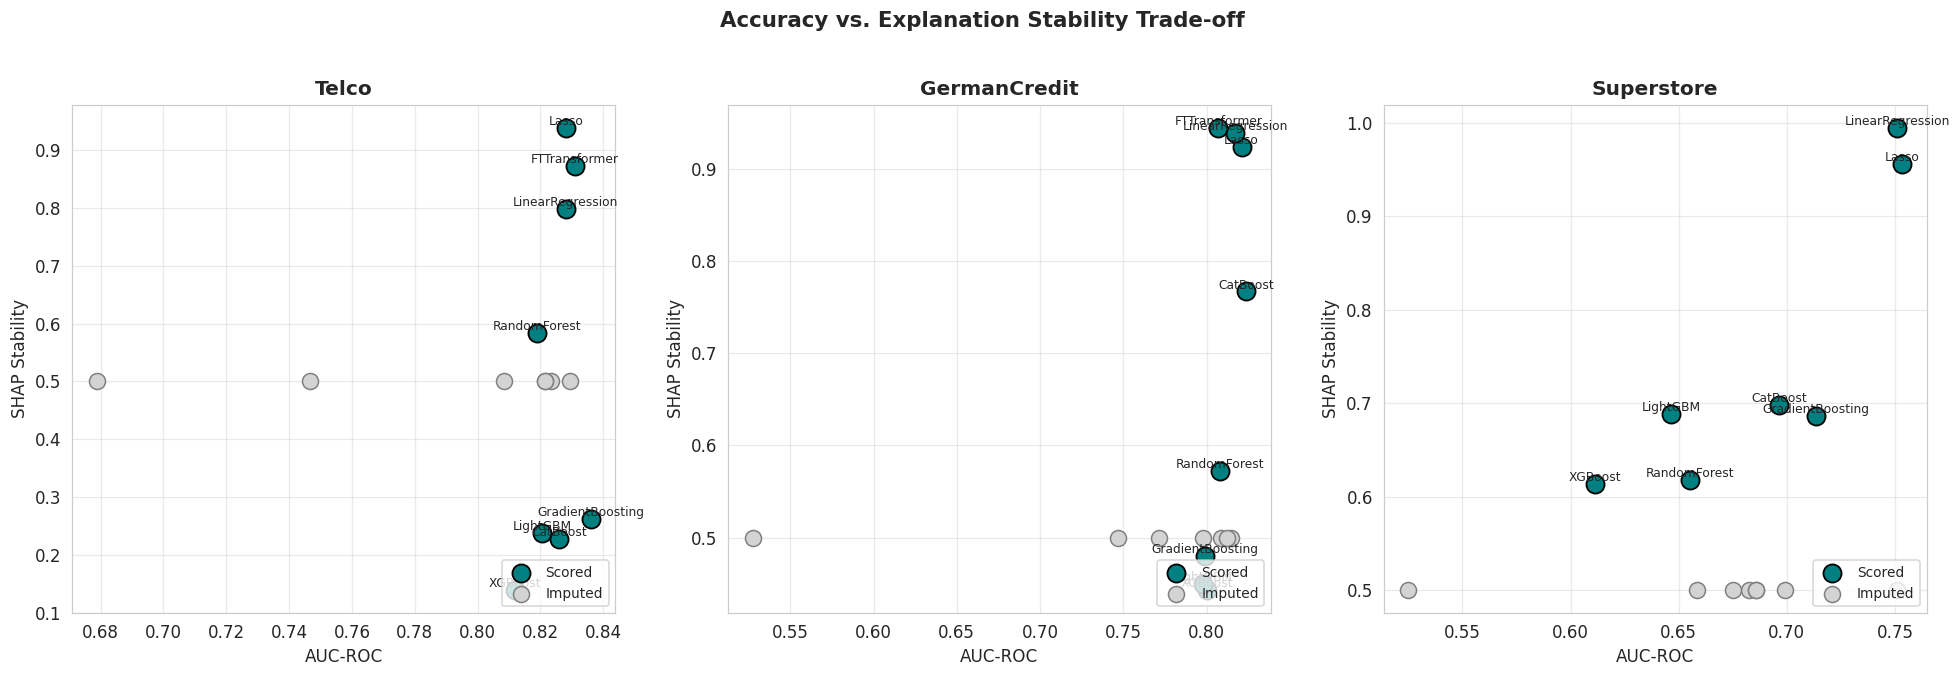

[Fig 1] Saved figures/auc_vs_stability.png/.pdf


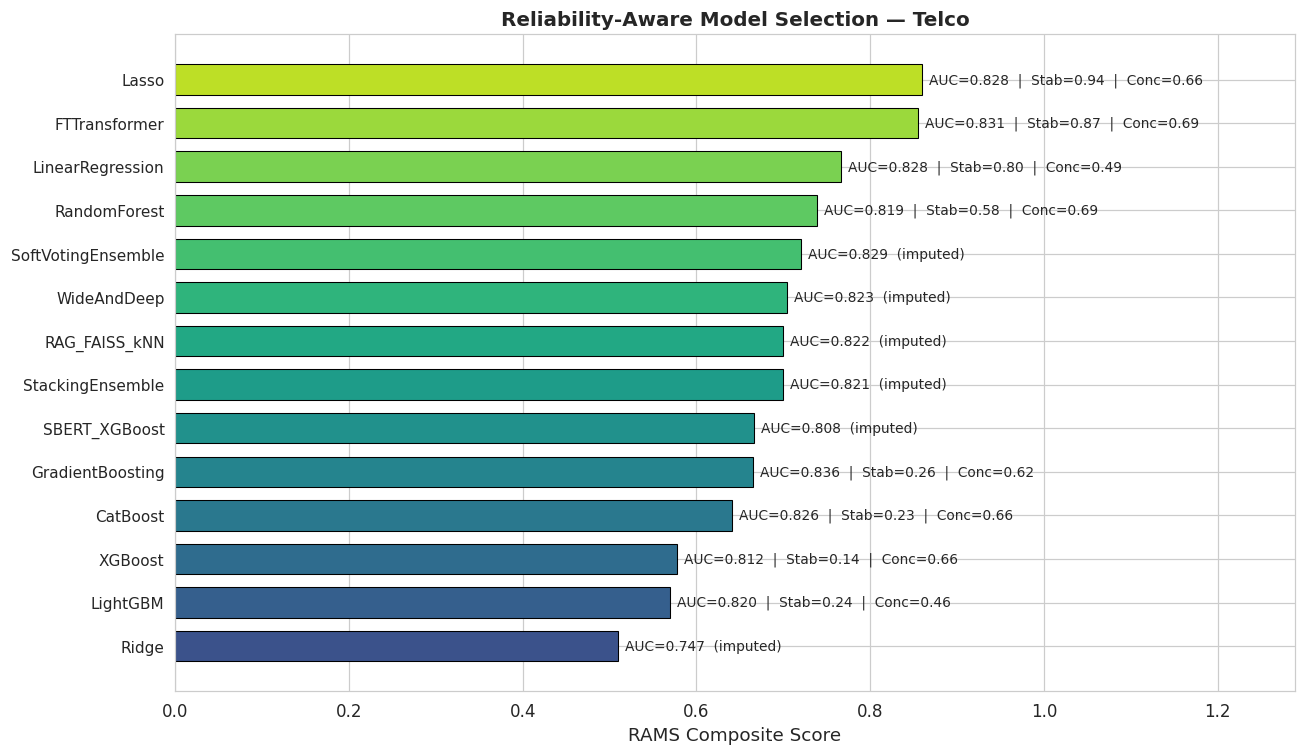

[Fig 2] Saved figures/rams_telco.png/.pdf


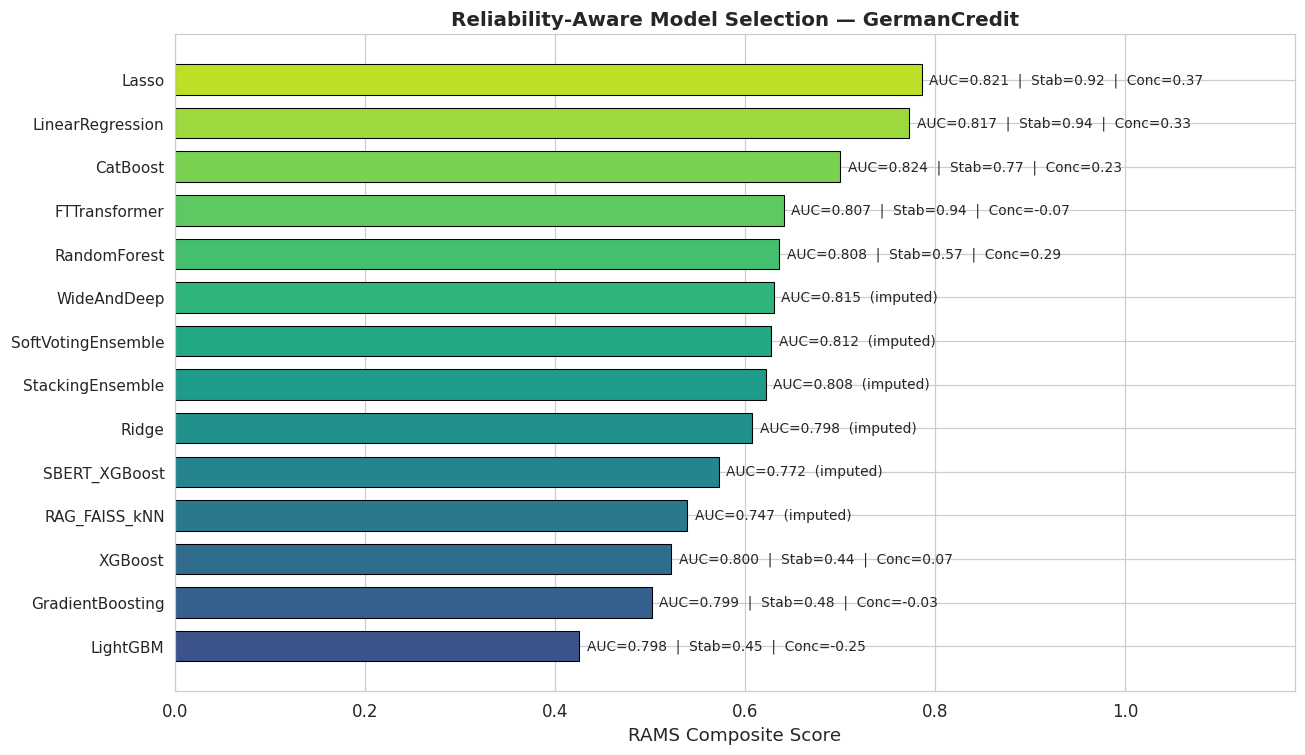

[Fig 2] Saved figures/rams_germancredit.png/.pdf


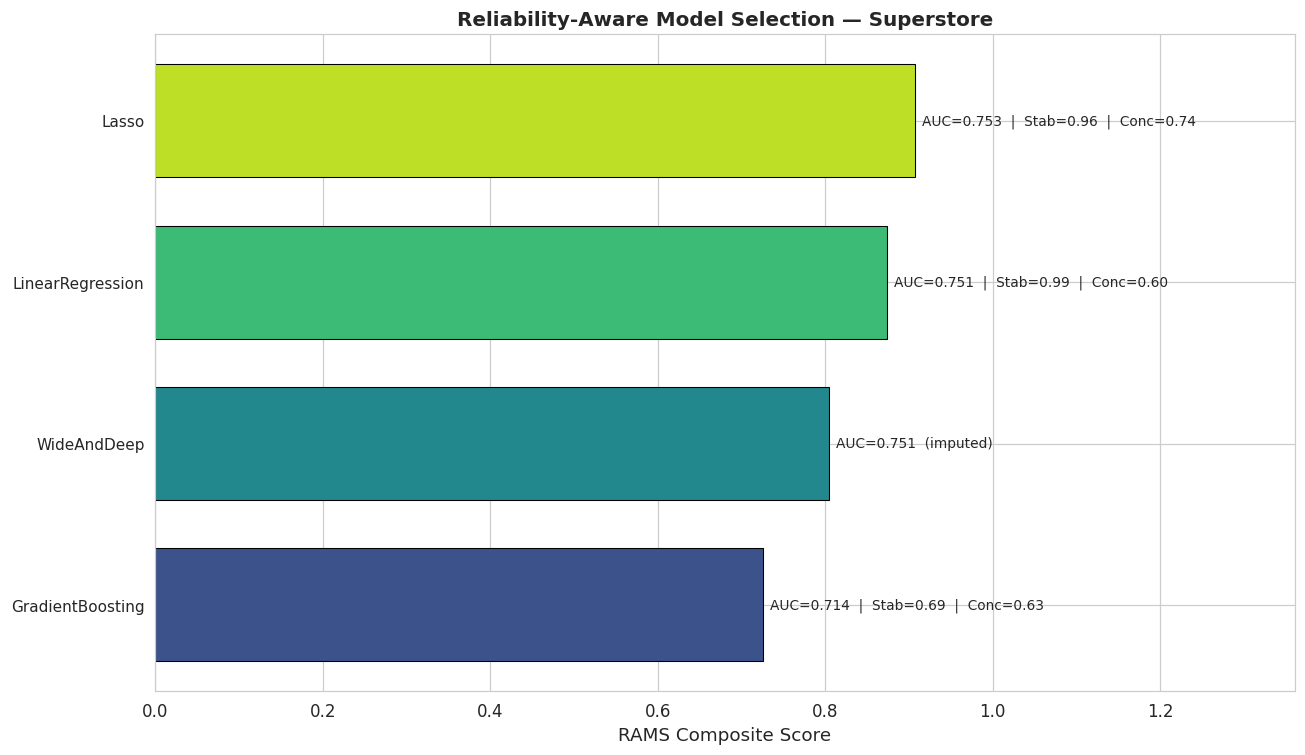

[Fig 2] Saved figures/rams_superstore.png/.pdf


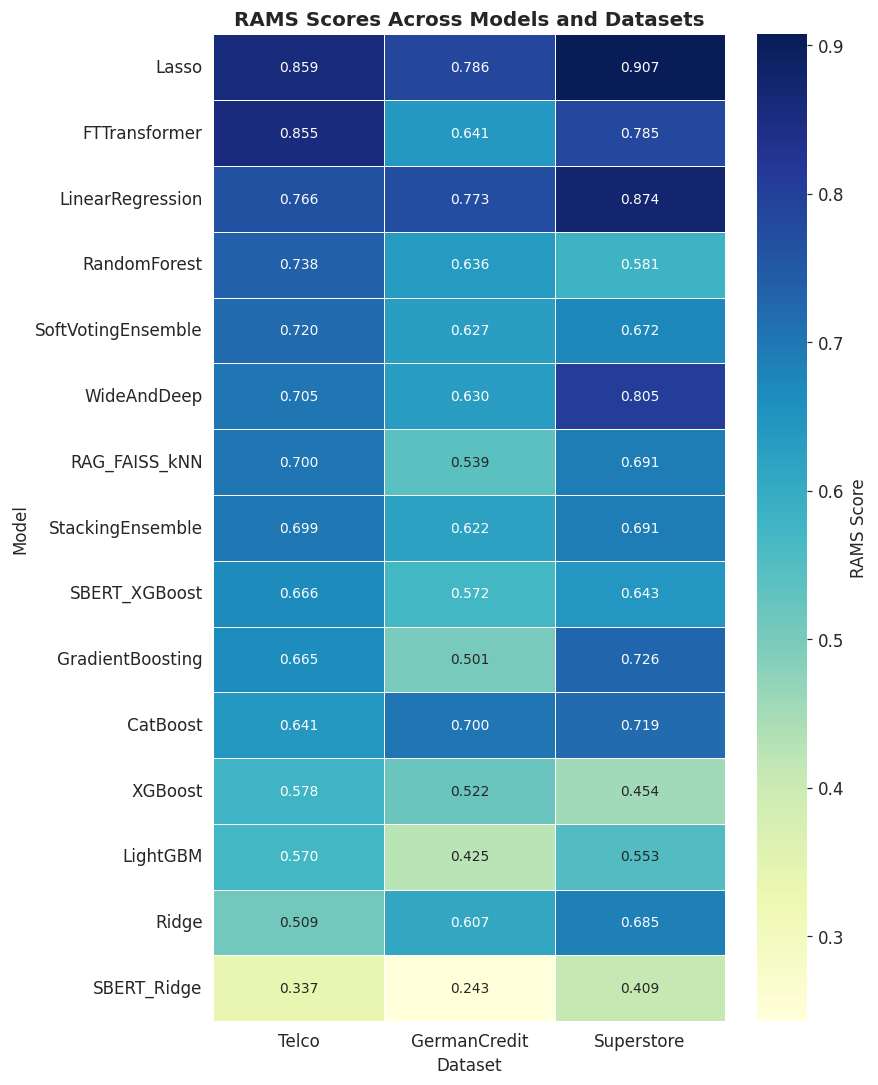

[Fig 3] Saved figures/rams_heatmap.png/.pdf


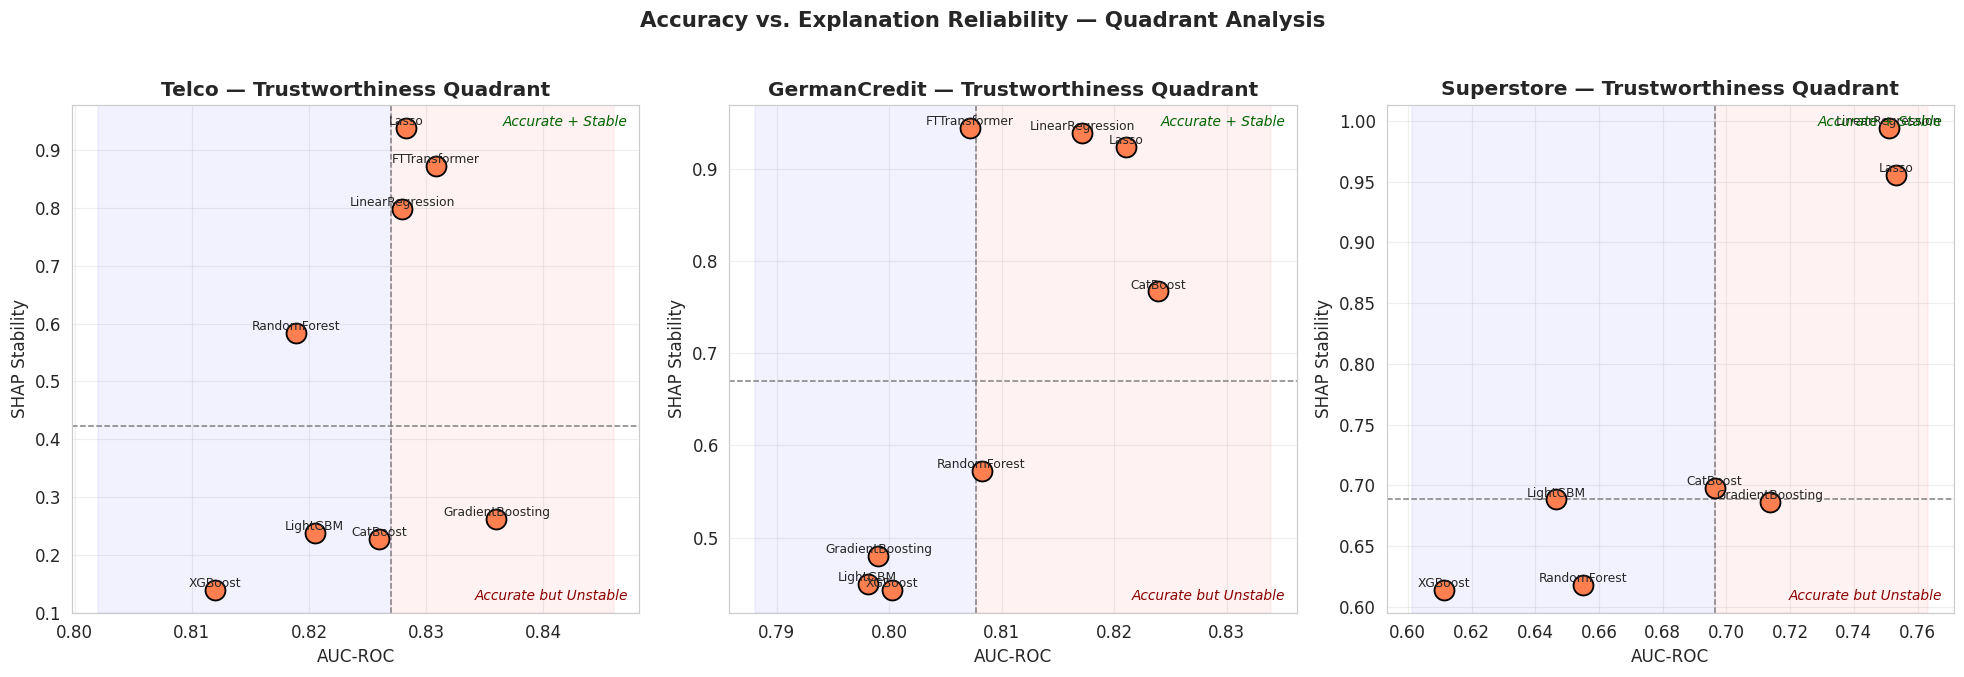

[Fig 4] Saved figures/trust_quadrant.png/.pdf

[OK] All 4 figures generated and displayed inline
     Files saved to ./figures/ as both PNG (300 dpi) and PDF


In [11]:
"""
================================================================================
STANDALONE PLOT GENERATOR — Reads JSON outputs, produces all manuscript figures
================================================================================
Requires:
  - results_extended.json       (from main pipeline)
  - rams_calibration_full.json  (from calibration cell)
Produces:
  - 4 figures, each saved as PNG + PDF and displayed inline
================================================================================
"""

import os, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Force inline display in Colab
%matplotlib inline
matplotlib.rcParams['figure.dpi'] = 110
matplotlib.rcParams['savefig.dpi'] = 300
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['font.size'] = 11

sns.set_style("whitegrid")
OUT = "figures"
os.makedirs(OUT, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------------------------
with open("results_extended.json") as f:
    results = json.load(f)

with open("rams_calibration_full.json") as f:
    scores = json.load(f)

print("[OK] Loaded results_extended.json and rams_calibration_full.json")


# ------------------------------------------------------------------------------
# 2. HELPERS (same as in the RAMS pipeline)
# ------------------------------------------------------------------------------
def build_rams_df(dataset):
    ds_results = results.get(dataset, {})
    ds_scores = scores.get(dataset, {})
    stab = ds_scores.get("stability", {})
    conc = ds_scores.get("concordance", {})

    rows = []
    for model, v in ds_results.items():
        if not isinstance(v, dict) or "auc_roc" not in v:
            continue
        rows.append({
            "Model": model,
            "AUC": v["auc_roc"],
            "Stability": stab.get(model, np.nan),
            "Concordance": conc.get(model, np.nan),
        })
    return pd.DataFrame(rows).set_index("Model")


def compute_rams(df, alpha=0.4, beta=0.3, gamma=0.3,
                 auc_floor=0.70, imputation="mean"):
    df = df.copy()
    auc_min, auc_max = df["AUC"].min(), df["AUC"].max()
    df["AUC_norm"] = (df["AUC"] - auc_min) / (auc_max - auc_min + 1e-9)
    df["Scored"] = df["Stability"].notna() & df["Concordance"].notna()

    if imputation == "mean":
        s_mean = df["Stability"].mean(skipna=True)
        c_mean = df["Concordance"].mean(skipna=True)
        s_mean = 0.5 if np.isnan(s_mean) else s_mean
        c_mean = 0.5 if np.isnan(c_mean) else c_mean
        df["Stability_f"] = df["Stability"].fillna(s_mean)
        df["Concordance_f"] = df["Concordance"].fillna(c_mean)
        df["RAMS"] = (alpha * df["AUC_norm"]
                      + beta * df["Stability_f"]
                      + gamma * df["Concordance_f"])

    df["Eligible"] = df["AUC"] >= auc_floor
    df["RAMS_rank"] = df["RAMS"].where(df["Eligible"]).rank(ascending=False)
    return df.sort_values("RAMS", ascending=False)


# ==============================================================================
# FIGURE 1 — AUC vs SHAP Stability (3 panels, one per dataset)
# ==============================================================================
def plot_auc_vs_stability():
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, ds in zip(axes, ["Telco", "GermanCredit", "Superstore"]):
        df = build_rams_df(ds)
        scored = df[df["Stability"].notna()]
        unscored = df[df["Stability"].isna()]

        if not scored.empty:
            ax.scatter(scored["AUC"], scored["Stability"],
                       s=140, c="teal", edgecolors="black",
                       linewidths=1.2, label="Scored", zorder=3)
        if not unscored.empty:
            ax.scatter(unscored["AUC"], [0.5]*len(unscored),
                       s=110, c="lightgray", edgecolors="gray",
                       linewidths=1, label="Imputed", zorder=2)
        for m, row in scored.iterrows():
            ax.annotate(m, (row["AUC"], row["Stability"]),
                        fontsize=8, ha="center", va="bottom")
        ax.set_xlabel("AUC-ROC")
        ax.set_ylabel("SHAP Stability")
        ax.set_title(ds, fontweight="bold")
        ax.legend(loc="lower right", fontsize=9)
        ax.grid(alpha=0.4)

    plt.suptitle("Accuracy vs. Explanation Stability Trade-off",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(f"{OUT}/auc_vs_stability.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT}/auc_vs_stability.pdf", bbox_inches="tight")
    plt.show()  # <-- DISPLAYS INLINE
    plt.close()
    print(f"[Fig 1] Saved {OUT}/auc_vs_stability.png/.pdf")


# ==============================================================================
# FIGURE 2 — RAMS Bar Charts (3 separate figures)
# ==============================================================================
def plot_rams_bars():
    for ds in ["Telco", "GermanCredit", "Superstore"]:
        df = build_rams_df(ds)
        ranked = compute_rams(df, imputation="mean")
        plot_df = ranked[ranked["Eligible"]].sort_values("RAMS", ascending=True)

        fig, ax = plt.subplots(figsize=(12, 7))
        colors = plt.cm.viridis(np.linspace(0.25, 0.9, len(plot_df)))
        ax.barh(plot_df.index, plot_df["RAMS"], color=colors,
                edgecolor="black", linewidth=0.7, height=0.7)

        for i, (idx, row) in enumerate(plot_df.iterrows()):
            if not np.isnan(row["Stability"]):
                label = (f"AUC={row['AUC']:.3f}  |  "
                         f"Stab={row['Stability']:.2f}  |  "
                         f"Conc={row['Concordance']:.2f}")
            else:
                label = f"AUC={row['AUC']:.3f}  (imputed)"
            ax.text(row["RAMS"] + 0.008, i, label,
                    va="center", fontsize=9)

        ax.set_xlabel("RAMS Composite Score", fontsize=12)
        ax.set_ylabel("")
        ax.set_title(f"Reliability-Aware Model Selection — {ds}",
                     fontsize=13, fontweight="bold")
        ax.set_xlim(0, plot_df["RAMS"].max() * 1.5)
        ax.tick_params(axis="y", labelsize=10)
        plt.tight_layout()
        plt.savefig(f"{OUT}/rams_{ds.lower()}.png",
                    dpi=300, bbox_inches="tight")
        plt.savefig(f"{OUT}/rams_{ds.lower()}.pdf", bbox_inches="tight")
        plt.show()  # <-- DISPLAYS INLINE
        plt.close()
        print(f"[Fig 2] Saved {OUT}/rams_{ds.lower()}.png/.pdf")


# ==============================================================================
# FIGURE 3 — RAMS Heatmap Across Models × Datasets
# ==============================================================================
def plot_rams_heatmap():
    all_rams = {}
    for ds in ["Telco", "GermanCredit", "Superstore"]:
        df = build_rams_df(ds)
        all_rams[ds] = compute_rams(df, imputation="mean")["RAMS"]
    heat = pd.DataFrame(all_rams).sort_values("Telco", ascending=False)

    fig, ax = plt.subplots(figsize=(8, 10))
    sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu",
                linewidths=0.5, ax=ax, cbar_kws={"label": "RAMS Score"},
                annot_kws={"size": 9})
    ax.set_title("RAMS Scores Across Models and Datasets",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Dataset", fontsize=11)
    ax.set_ylabel("Model", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{OUT}/rams_heatmap.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT}/rams_heatmap.pdf", bbox_inches="tight")
    plt.show()  # <-- DISPLAYS INLINE
    plt.close()
    print(f"[Fig 3] Saved {OUT}/rams_heatmap.png/.pdf")


# ==============================================================================
# FIGURE 4 — Trustworthiness Quadrant (3 panels)
# ==============================================================================
def plot_trust_quadrant():
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, ds in zip(axes, ["Telco", "GermanCredit", "Superstore"]):
        df = build_rams_df(ds)
        scored = df[df["Stability"].notna()]
        if scored.empty:
            ax.set_title(f"{ds} (no scored models)")
            continue

        med_auc = scored["AUC"].median()
        med_stab = scored["Stability"].median()

        # Quadrant shading
        ax.axvspan(scored["AUC"].min() - 0.01, med_auc,
                   alpha=0.05, color="blue")
        ax.axvspan(med_auc, scored["AUC"].max() + 0.01,
                   alpha=0.05, color="red")
        ax.axvline(med_auc, color="gray", linestyle="--", linewidth=1)
        ax.axhline(med_stab, color="gray", linestyle="--", linewidth=1)

        ax.scatter(scored["AUC"], scored["Stability"],
                   s=170, c="coral", edgecolors="black", linewidths=1.2,
                   zorder=3)

        for m, row in scored.iterrows():
            ax.annotate(m, (row["AUC"], row["Stability"]),
                        fontsize=8, ha="center", va="bottom")

        # Quadrant labels
        ax.text(0.98, 0.98, "Accurate + Stable",
                transform=ax.transAxes, ha="right", va="top",
                fontsize=9, style="italic", color="darkgreen")
        ax.text(0.98, 0.02, "Accurate but Unstable",
                transform=ax.transAxes, ha="right", va="bottom",
                fontsize=9, style="italic", color="darkred")

        ax.set_xlabel("AUC-ROC")
        ax.set_ylabel("SHAP Stability")
        ax.set_title(f"{ds} — Trustworthiness Quadrant",
                     fontweight="bold")
        ax.grid(alpha=0.3)

    plt.suptitle("Accuracy vs. Explanation Reliability — Quadrant Analysis",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(f"{OUT}/trust_quadrant.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT}/trust_quadrant.pdf", bbox_inches="tight")
    plt.show()  # <-- DISPLAYS INLINE
    plt.close()
    print(f"[Fig 4] Saved {OUT}/trust_quadrant.png/.pdf")


# ==============================================================================
# RUN ALL FIGURES
# ==============================================================================
print("\n" + "="*80)
print("GENERATING ALL PUBLICATION FIGURES")
print("="*80)

plot_auc_vs_stability()
plot_rams_bars()
plot_rams_heatmap()
plot_trust_quadrant()

print("\n" + "="*80)
print("[OK] All 4 figures generated and displayed inline")
print(f"     Files saved to ./{OUT}/ as both PNG (300 dpi) and PDF")
print("="*80)